In [1]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

n_records = 1000

# Generate dummy data for 7 specific loan-related columns
data = {
    'Loan_ID': [f'LP{i:04d}' for i in range(1, n_records + 1)],
    'Applicant_Income': np.random.randint(1500, 15000, size=n_records),
    'Coapplicant_Income': np.random.choice([0, np.random.randint(1000, 8000)], size=n_records, p=[0.4, 0.6]),
    'Loan_Amount': np.random.randint(50, 500, size=n_records) * 1000, # In dollars
    'Loan_Amount_Term': np.random.choice([120, 180, 240, 360], size=n_records, p=[0.05, 0.1, 0.05, 0.8]),
    'Credit_History': np.random.choice([1, 0], size=n_records, p=[0.85, 0.15]),
    'Loan_Status': np.random.choice(['Y', 'N'], size=n_records, p=[0.7, 0.3])
}

# Create DataFrame
df_loans = pd.DataFrame(data)

# Display dataset info and the first few rows
print(f"Dataset Shape: {df_loans.shape}")
print("\nFirst 5 rows:")
print(df_loans.head())

Dataset Shape: (1000, 7)

First 5 rows:
  Loan_ID  Applicant_Income  Coapplicant_Income  Loan_Amount  \
0  LP0001              8770                   0       490000   
1  LP0002              2360                   0       303000   
2  LP0003              6890                7196       458000   
3  LP0004             14918                   0       307000   
4  LP0005              6691                7196       369000   

   Loan_Amount_Term  Credit_History Loan_Status  
0               180               1           Y  
1               360               1           Y  
2               360               1           Y  
3               360               1           N  
4               360               1           N  


Model Accuracy: 0.7050

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        59
           1       0.70      1.00      0.83       141

    accuracy                           0.70       200
   macro avg       0.35      0.50      0.41       200
weighted avg       0.50      0.70      0.58       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


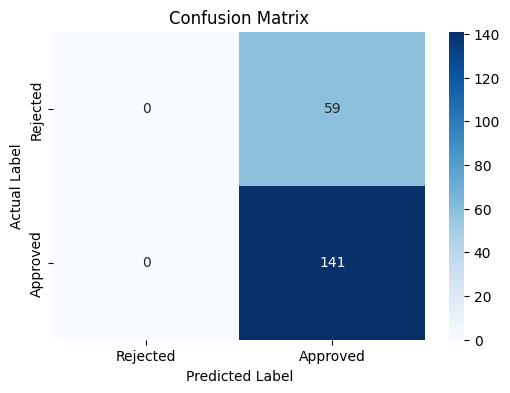

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare features and target variable
# Define numeric and categorical features
X = df_loans[['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Amount_Term', 'Credit_History']]
y = df_loans['Loan_Status'].map({'Y': 1, 'N': 0}) # Encode target as binary (1 for Yes, 0 for No)

# 2. Split dataset into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardize/scale numeric features
scaler = StandardScaler()
# Fit scaler on training set, then transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Initialize and fit Logistic Regression model
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 5. Make predictions
y_pred = log_reg.predict(X_test_scaled)

# 6. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

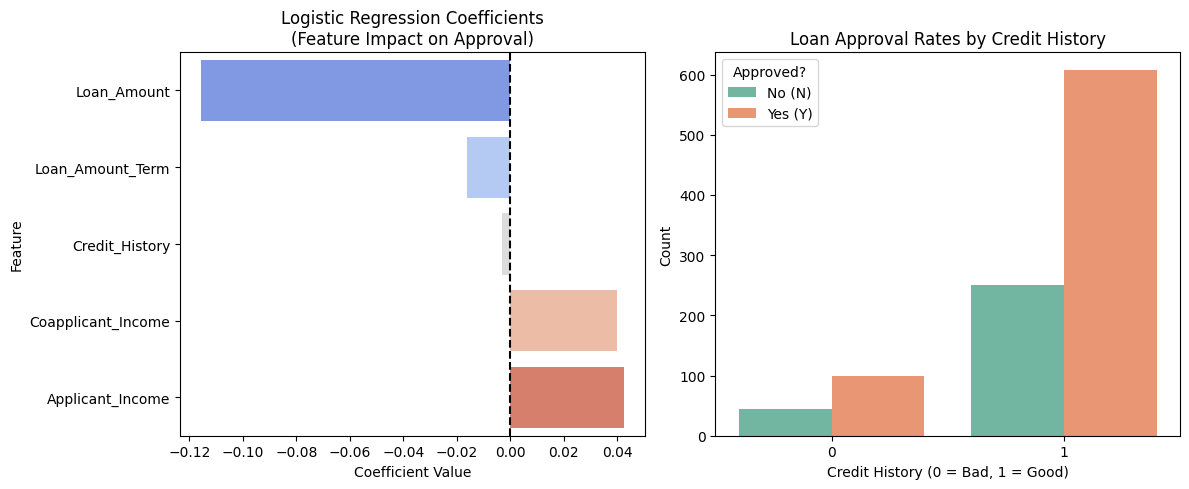

Approval Rate by Credit History:
Loan_Status            N         Y
Credit_History                    
0               0.307692  0.692308
1               0.291715  0.708285


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Feature Importance (Coefficients) Plot
coefficients = log_reg.coef_[0]
features = X.columns
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': coefficients}).sort_values(by='Coefficient')

plt.figure(figsize=(12, 5))

# Subplot 1: Model Coefficients
plt.subplot(1, 2, 1)
sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette='coolwarm', hue='Feature', legend=False)
plt.axvline(x=0, color='black', linestyle='--')
plt.title('Logistic Regression Coefficients\n(Feature Impact on Approval)')
plt.xlabel('Coefficient Value')

# Subplot 2: Bias Check on Credit History
plt.subplot(1, 2, 2)
sns.countplot(x='Credit_History', hue='Loan_Status', data=df_loans, palette='Set2')
plt.title('Loan Approval Rates by Credit History')
plt.xlabel('Credit History (0 = Bad, 1 = Good)')
plt.ylabel('Count')
plt.legend(title='Approved?', labels=['No (N)', 'Yes (Y)'])

plt.tight_layout()
plt.show()

# Print statistical summary to evaluate why there is bias
print("Approval Rate by Credit History:")
print(df_loans.groupby('Credit_History')['Loan_Status'].value_counts(normalize=True).unstack())

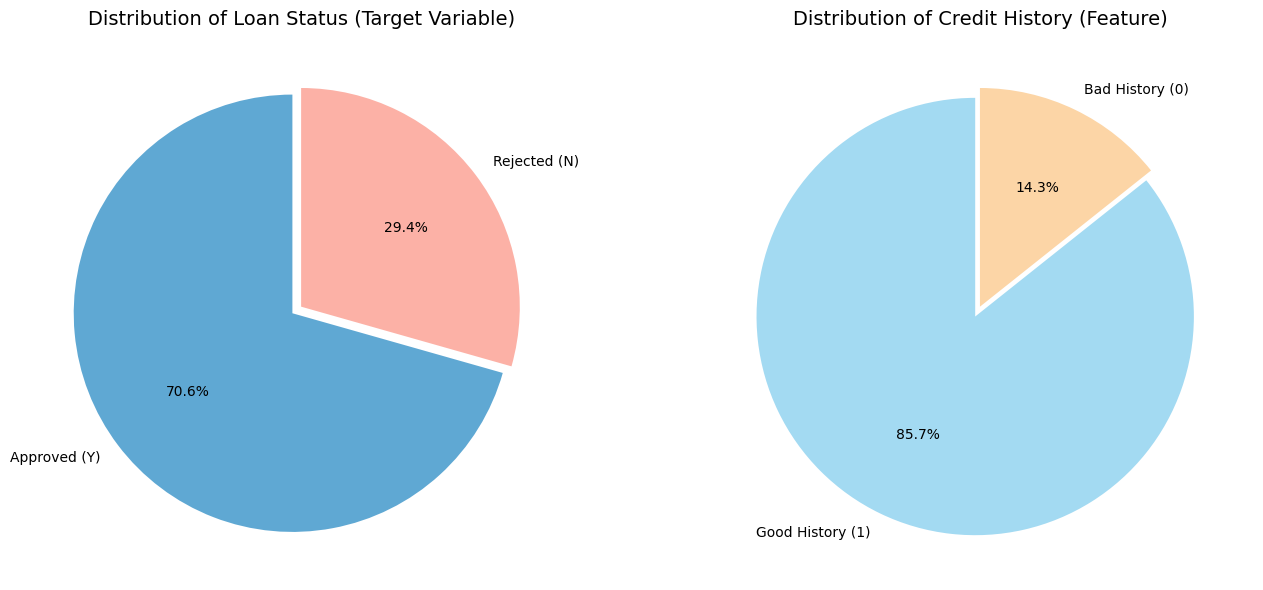

In [5]:
import matplotlib.pyplot as plt

# Calculate counts for Loan Status and Credit History
loan_status_counts = df_loans['Loan_Status'].value_counts()
credit_history_counts = df_loans['Credit_History'].value_counts()

# Create subplots for the pie charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart 1: Loan Status
axes[0].pie(
    loan_status_counts,
    labels=['Approved (Y)', 'Rejected (N)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#5fa8d3', '#fcb1a6'],
    explode=(0.05, 0)
)
axes[0].set_title('Distribution of Loan Status (Target Variable)', fontsize=14)

# Pie chart 2: Credit History
axes[1].pie(
    credit_history_counts,
    labels=['Good History (1)', 'Bad History (0)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#a3daf2', '#fcd5a6'],
    explode=(0.05, 0)
)
axes[1].set_title('Distribution of Credit History (Feature)', fontsize=14)

plt.tight_layout()
plt.show()

In [6]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import numpy as np

# Create input fields
app_income_input = widgets.IntSlider(value=5000, min=1500, max=15000, step=100, description='Applicant Income ($):', style={'description_width': 'initial'})
coapp_income_input = widgets.IntSlider(value=0, min=0, max=8000, step=100, description='Coapplicant Income ($):', style={'description_width': 'initial'})
loan_amount_input = widgets.IntSlider(value=150000, min=50000, max=500000, step=5000, description='Loan Amount ($):', style={'description_width': 'initial'})
loan_term_input = widgets.Dropdown(options=[120, 180, 240, 360], value=360, description='Loan Term (Days):', style={'description_width': 'initial'})
credit_history_input = widgets.Dropdown(options=[('Good History (1)', 1), ('Bad History (0)', 0)], value=1, description='Credit History:', style={'description_width': 'initial'})

predict_button = widgets.Button(description='Test Model', button_style='primary')
output_area = widgets.Output()

def make_prediction(b):
    with output_area:
        clear_output()
        # Gather inputs into a dataframe format matching X
        user_data = pd.DataFrame({
            'Applicant_Income': [app_income_input.value],
            'Coapplicant_Income': [coapp_income_input.value],
            'Loan_Amount': [loan_amount_input.value],
            'Loan_Amount_Term': [loan_term_input.value],
            'Credit_History': [credit_history_input.value]
        })

        # Standardize inputs using the previously fitted scaler
        user_data_scaled = scaler.transform(user_data)

        # Get model prediction and probability
        prediction = log_reg.predict(user_data_scaled)[0]
        probabilities = log_reg.predict_proba(user_data_scaled)[0]

        status = "APPROVED (Y)" if prediction == 1 else "REJECTED (N)"
        color = "green" if prediction == 1 else "red"

        print("--- Prediction Result ---")
        print(f"Predicted Status: {status}")
        print(f"Probability of Approval: {probabilities[1]:.2%}")
        print(f"Probability of Rejection: {probabilities[0]:.2%}")

# Bind button click to prediction function
predict_button.on_click(make_prediction)

# Display UI Layout
ui = widgets.VBox([
    widgets.HTML(value="<h3>Enter Customer Details to Test Loan Approval Model:</h3>"),
    app_income_input,
    coapp_income_input,
    loan_amount_input,
    loan_term_input,
    credit_history_input,
    widgets.Label(),
    predict_button,
    output_area
])

display(ui)